# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Data Processing and Linear Regression Exploration
*By Mark Lambert - C00192497*

---

In third year I built and deployed a LastFm scrobbling program, which familiarised me with the LastFM API. 

I decided for my Data Science & Machine Learning Portfolio that using this data would be interesting and applicable.
        
The first step is to connect with the API using an API key, and then pull all of the scrobbles using the ```User.getRecentTracks``` and ```User.getLovedTracks``` endpoints.

```%pip install pandas scikit-learn matplotlib```

In [1]:
import requests
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import make_pipeline

API_KEY = ' api key'
USERNAME = ' username'

all_tracks = []
page = 1
total_pages = 1

while page <= total_pages:
    response = requests.get('http://ws.audioscrobbler.com/2.0/', params={
        'method': 'user.getrecenttracks',
        'user': USERNAME,
        'api_key': API_KEY,
        'format': 'json',
        'limit': 200,
        'page': page
    })
    data = response.json()
    if page == 1:
        total_pages = int(data['recenttracks']['@attr']['totalPages'])
    all_tracks.extend(data['recenttracks']['track'])
    page += 1

The data's raw columns.

The ones that this portfolio will focus on are **artist, album, name and date**. ```@attr``` holds songs that are marked ```nowplaying = true```. 

As such, anything with this attribute will also be ignored later on.

In [2]:
scrobblesResponse = pd.DataFrame(all_tracks)

scrobblesResponse.columns

Index(['artist', 'streamable', 'image', 'mbid', 'album', 'name', '@attr',
       'url', 'date'],
      dtype='str')

The raw data shows that the actual readable details for each artist, album are embedded with a ```#text``` key in a dictionary, which must be extracted

In [3]:
scrobblesResponse

,artist,streamable,image,mbid,album,name,@attr,url,date
0,{'mbid': '06fb1c8b-566e-4cb2-985b-b467c90781d4...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",0857f923-ee45-3947-adee-665f131963c2,{'mbid': '90d15fbb-dba5-43e9-aa9a-6a519ce6b246...,Jungle,{'nowplaying': 'true'},https://www.last.fm/music/Jimi+Hendrix/_/Jungle,NaN
1,{'mbid': 'f46bd570-5768-462e-b84c-c7c993bbf47e...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",53fad7e6-0b45-4fdf-ae65-53da69546783,"{'mbid': '', '#text': 'The Long Run (2013 Rema...",I Can't Tell You Why - 2013 Remaster,NaN,https://www.last.fm/music/Eagles/_/I+Can%27t+T...,"{'uts': '1791983602', '#text': '14 Oct 2026, 1..."
2,{'mbid': 'ce332022-92f1-4909-ac4c-c7aa0ca469f1...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",0dbaf9cf-12ba-3717-99fb-cec2066b84be,{'mbid': '0056afca-a773-4180-b523-a307aa2ca74b...,Another,NaN,https://www.last.fm/music/Ataxia/_/Another,"{'uts': '1791983297', '#text': '14 Oct 2026, 1..."
3,{'mbid': '3ae2fb37-8a23-429d-9920-bac811c4fc22...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",1b46708a-9bb0-456c-ba1e-f976497a82ff,{'mbid': '0435a31f-28ff-4799-8c63-c746aeef8ac5...,Would You Fight for My Love?,NaN,https://www.last.fm/music/Jack+White/_/Would+Y...,"{'uts': '1791982775', '#text': '14 Oct 2026, 1..."
4,{'mbid': '3ae2fb37-8a23-429d-9920-bac811c4fc22...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",dba84167-c823-493a-aaa9-124d81eb68ce,{'mbid': 'cbe2c86a-a2b9-420d-906e-64d7ddf8f041...,Neighbors Blues,NaN,https://www.last.fm/music/Jack+White/_/Neighbo...,"{'uts': '1791982528', '#text': '14 Oct 2026, 1..."
...,...,...,...,...,...,...,...,...,...
18053,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",362c85ba-c79b-478e-8321-0383c3ac8101,{'mbid': '0d2cb66c-3a32-4f81-b977-9231c461c34a...,Why Won't They Talk to Me?,NaN,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,"{'uts': '1763463648', '#text': '18 Nov 2025, 1..."
18054,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",6f93589f-4a47-4a9d-9274-09a0f437ad15,{'mbid': '10ac58ca-0655-4b16-a6cb-58fdc309de0a...,Over,NaN,https://www.last.fm/music/Portishead/_/Over,"{'uts': '1763463370', '#text': '18 Nov 2025, 1..."
18055,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",6da0b598-d9cf-4f62-8376-bc3181e509af,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Obsolete,NaN,https://www.last.fm/music/Tame+Impala/_/Obsolete,"{'uts': '1763462844', '#text': '18 Nov 2025, 1..."
18056,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",ad79b526-8df8-4e79-8756-0607df153e59,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Piece Of Heaven,NaN,https://www.last.fm/music/Tame+Impala/_/Piece+...,"{'uts': '1763462559', '#text': '18 Nov 2025, 1..."


Next, as per [Carlos Medina's article](https://medium.com/hemisferios/using-the-last-fm-api-to-extract-data-and-analyzing-it-with-python-part-1-ffe96f812455), first we must select the colums of interest and, as the column name is obscure I have chosen to rename it to **song**

In [4]:
scrobbles = scrobblesResponse

scrobbles = scrobbles[['artist', 'album', 'name', 'url', 'date']]
scrobbles.rename(columns={'name': 'song'}, inplace=True)
scrobbles

,artist,album,song,url,date
0,{'mbid': '06fb1c8b-566e-4cb2-985b-b467c90781d4...,{'mbid': '90d15fbb-dba5-43e9-aa9a-6a519ce6b246...,Jungle,https://www.last.fm/music/Jimi+Hendrix/_/Jungle,NaN
1,{'mbid': 'f46bd570-5768-462e-b84c-c7c993bbf47e...,"{'mbid': '', '#text': 'The Long Run (2013 Rema...",I Can't Tell You Why - 2013 Remaster,https://www.last.fm/music/Eagles/_/I+Can%27t+T...,"{'uts': '1791983602', '#text': '14 Oct 2026, 1..."
2,{'mbid': 'ce332022-92f1-4909-ac4c-c7aa0ca469f1...,{'mbid': '0056afca-a773-4180-b523-a307aa2ca74b...,Another,https://www.last.fm/music/Ataxia/_/Another,"{'uts': '1791983297', '#text': '14 Oct 2026, 1..."
3,{'mbid': '3ae2fb37-8a23-429d-9920-bac811c4fc22...,{'mbid': '0435a31f-28ff-4799-8c63-c746aeef8ac5...,Would You Fight for My Love?,https://www.last.fm/music/Jack+White/_/Would+Y...,"{'uts': '1791982775', '#text': '14 Oct 2026, 1..."
4,{'mbid': '3ae2fb37-8a23-429d-9920-bac811c4fc22...,{'mbid': 'cbe2c86a-a2b9-420d-906e-64d7ddf8f041...,Neighbors Blues,https://www.last.fm/music/Jack+White/_/Neighbo...,"{'uts': '1791982528', '#text': '14 Oct 2026, 1..."
...,...,...,...,...,...
18053,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,{'mbid': '0d2cb66c-3a32-4f81-b977-9231c461c34a...,Why Won't They Talk to Me?,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,"{'uts': '1763463648', '#text': '18 Nov 2025, 1..."
18054,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,{'mbid': '10ac58ca-0655-4b16-a6cb-58fdc309de0a...,Over,https://www.last.fm/music/Portishead/_/Over,"{'uts': '1763463370', '#text': '18 Nov 2025, 1..."
18055,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Obsolete,https://www.last.fm/music/Tame+Impala/_/Obsolete,"{'uts': '1763462844', '#text': '18 Nov 2025, 1..."
18056,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Piece Of Heaven,https://www.last.fm/music/Tame+Impala/_/Piece+...,"{'uts': '1763462559', '#text': '18 Nov 2025, 1..."


Next, convert the ```artist, album``` and ```dates``` to strings

In [5]:
scrobbles['artist'] = scrobbles['artist'].astype(str)
scrobbles['album'] = scrobbles['album'].astype(str)
scrobbles['date'] = scrobbles['date'].astype(str)

Extract the embedded ```#text``` attribute from each of the ```artist, album``` and ```date``` fields

In [6]:
scrobbles[['mbid2','artist']]=scrobbles['artist'].str.split("#text':", n = 1, expand = True)
scrobbles= scrobbles.drop('mbid2', axis=1)
scrobbles[['mbid3','album']]=scrobbles['album'].str.split("#text':", n = 1, expand = True)
scrobbles= scrobbles.drop('mbid3', axis=1)
scrobbles[['uts','date']]=scrobbles['date'].str.split("#text':", n = 1, expand = True)
scrobbles.head()

,artist,album,song,url,date,uts
0,'Jimi Hendrix'},'Both Sides of the Sky'},Jungle,https://www.last.fm/music/Jimi+Hendrix/_/Jungle,NaN,NaN
1,'Eagles'},'The Long Run (2013 Remaster)'},I Can't Tell You Why - 2013 Remaster,https://www.last.fm/music/Eagles/_/I+Can%27t+T...,"'14 Oct 2026, 13:13'}","{'uts': '1791983602', '"
2,'Ataxia'},'Automatic Writing'},Another,https://www.last.fm/music/Ataxia/_/Another,"'14 Oct 2026, 13:08'}","{'uts': '1791983297', '"
3,'Jack White'},'Lazaretto'},Would You Fight for My Love?,https://www.last.fm/music/Jack+White/_/Would+Y...,"'14 Oct 2026, 12:59'}","{'uts': '1791982775', '"
4,'Jack White'},'Frozen Charlotte'},Neighbors Blues,https://www.last.fm/music/Jack+White/_/Neighbo...,"'14 Oct 2026, 12:55'}","{'uts': '1791982528', '"


Removing the ```}``` and ```'``` characters from the ```artist and album``` entries

In [7]:
scrobbles['artist'] = scrobbles['artist'].str.strip("}'\" ")
scrobbles['album'] = scrobbles['album'].str.strip("}'\" ")
scrobbles.head()

,artist,album,song,url,date,uts
0,Jimi Hendrix,Both Sides of the Sky,Jungle,https://www.last.fm/music/Jimi+Hendrix/_/Jungle,NaN,NaN
1,Eagles,The Long Run (2013 Remaster),I Can't Tell You Why - 2013 Remaster,https://www.last.fm/music/Eagles/_/I+Can%27t+T...,"'14 Oct 2026, 13:13'}","{'uts': '1791983602', '"
2,Ataxia,Automatic Writing,Another,https://www.last.fm/music/Ataxia/_/Another,"'14 Oct 2026, 13:08'}","{'uts': '1791983297', '"
3,Jack White,Lazaretto,Would You Fight for My Love?,https://www.last.fm/music/Jack+White/_/Would+Y...,"'14 Oct 2026, 12:59'}","{'uts': '1791982775', '"
4,Jack White,Frozen Charlotte,Neighbors Blues,https://www.last.fm/music/Jack+White/_/Neighbo...,"'14 Oct 2026, 12:55'}","{'uts': '1791982528', '"


The ```date and uts``` fields also need to be stripped of the remaining dirty characters. I have also chosen to rename uts to **timestamp** as it is more descriptive.

In [8]:
scrobbles['date'] = scrobbles['date'].str.strip("}'\" ")
scrobbles['uts'] = scrobbles['uts'].str.strip("{uts':','\" ")
scrobbles.rename(columns={'uts': 'timestamp'}, inplace=True)
scrobbles.head()

,artist,album,song,url,date,timestamp
0,Jimi Hendrix,Both Sides of the Sky,Jungle,https://www.last.fm/music/Jimi+Hendrix/_/Jungle,NaN,NaN
1,Eagles,The Long Run (2013 Remaster),I Can't Tell You Why - 2013 Remaster,https://www.last.fm/music/Eagles/_/I+Can%27t+T...,"14 Oct 2026, 13:13",1791983602
2,Ataxia,Automatic Writing,Another,https://www.last.fm/music/Ataxia/_/Another,"14 Oct 2026, 13:08",1791983297
3,Jack White,Lazaretto,Would You Fight for My Love?,https://www.last.fm/music/Jack+White/_/Would+Y...,"14 Oct 2026, 12:59",1791982775
4,Jack White,Frozen Charlotte,Neighbors Blues,https://www.last.fm/music/Jack+White/_/Neighbo...,"14 Oct 2026, 12:55",1791982528


Next, the date field must be converted into a date only field

In [9]:
scrobbles['date'] = pd.to_datetime(scrobbles['date'], unit='s')
scrobbles['date_only'] = scrobbles['date'].dt.date
scrobbles

,artist,album,song,url,date,timestamp,date_only
0,Jimi Hendrix,Both Sides of the Sky,Jungle,https://www.last.fm/music/Jimi+Hendrix/_/Jungle,NaT,NaN,NaT
1,Eagles,The Long Run (2013 Remaster),I Can't Tell You Why - 2013 Remaster,https://www.last.fm/music/Eagles/_/I+Can%27t+T...,2026-10-14 13:13:00,1791983602,2026-10-14
2,Ataxia,Automatic Writing,Another,https://www.last.fm/music/Ataxia/_/Another,2026-10-14 13:08:00,1791983297,2026-10-14
3,Jack White,Lazaretto,Would You Fight for My Love?,https://www.last.fm/music/Jack+White/_/Would+Y...,2026-10-14 12:59:00,1791982775,2026-10-14
4,Jack White,Frozen Charlotte,Neighbors Blues,https://www.last.fm/music/Jack+White/_/Neighbo...,2026-10-14 12:55:00,1791982528,2026-10-14
...,...,...,...,...,...,...,...
18053,Tame Impala,Lonerism,Why Won't They Talk to Me?,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,2025-11-18 11:00:00,1763463648,2025-11-18
18054,Portishead,Portishead,Over,https://www.last.fm/music/Portishead/_/Over,2025-11-18 10:56:00,1763463370,2025-11-18
18055,Tame Impala,Deadbeat,Obsolete,https://www.last.fm/music/Tame+Impala/_/Obsolete,2025-11-18 10:47:00,1763462844,2025-11-18
18056,Tame Impala,Deadbeat,Piece Of Heaven,https://www.last.fm/music/Tame+Impala/_/Piece+...,2025-11-18 10:42:00,1763462559,2025-11-18


Finally, the row which contains NaN must be removed, as this was a song that had the ```@attr``` of ```nowplaying = true```, so it should not count as a fully scrobbled song

In [10]:
scrobbles = scrobbles.dropna(subset=['date'])
scrobbles

,artist,album,song,url,date,timestamp,date_only
1,Eagles,The Long Run (2013 Remaster),I Can't Tell You Why - 2013 Remaster,https://www.last.fm/music/Eagles/_/I+Can%27t+T...,2026-10-14 13:13:00,1791983602,2026-10-14
2,Ataxia,Automatic Writing,Another,https://www.last.fm/music/Ataxia/_/Another,2026-10-14 13:08:00,1791983297,2026-10-14
3,Jack White,Lazaretto,Would You Fight for My Love?,https://www.last.fm/music/Jack+White/_/Would+Y...,2026-10-14 12:59:00,1791982775,2026-10-14
4,Jack White,Frozen Charlotte,Neighbors Blues,https://www.last.fm/music/Jack+White/_/Neighbo...,2026-10-14 12:55:00,1791982528,2026-10-14
5,Jack White,no name,What's The Rumpus?,https://www.last.fm/music/Jack+White/_/What%27...,2026-10-14 12:50:00,1791982224,2026-10-14
...,...,...,...,...,...,...,...
18053,Tame Impala,Lonerism,Why Won't They Talk to Me?,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,2025-11-18 11:00:00,1763463648,2025-11-18
18054,Portishead,Portishead,Over,https://www.last.fm/music/Portishead/_/Over,2025-11-18 10:56:00,1763463370,2025-11-18
18055,Tame Impala,Deadbeat,Obsolete,https://www.last.fm/music/Tame+Impala/_/Obsolete,2025-11-18 10:47:00,1763462844,2025-11-18
18056,Tame Impala,Deadbeat,Piece Of Heaven,https://www.last.fm/music/Tame+Impala/_/Piece+...,2025-11-18 10:42:00,1763462559,2025-11-18


Then, three new columns- ```hour``` ```tod``` ```month``` are added. First, the time has to be converted to Dublin's time. Then, we can call the time_of_day function to classify between the four periods of a day: **morning, afternoon, evening and night.**

In [11]:
def time_of_day(hour):
    if hour >= 22 or hour < 5:
        return 'night'
    if hour < 12:
        return 'morning'
    if hour < 17:
        return 'afternoon'
    return 'evening'

local_time = scrobbles['date'].dt.tz_localize('UTC').dt.tz_convert('Europe/Dublin')
scrobbles['hour'] = local_time.dt.hour
scrobbles['tod'] = scrobbles['hour'].apply(time_of_day)
scrobbles['month'] = scrobbles['date'].dt.to_period('M')
scrobbles.head()

,artist,album,song,url,date,timestamp,date_only,hour,tod,month
1,Eagles,The Long Run (2013 Remaster),I Can't Tell You Why - 2013 Remaster,https://www.last.fm/music/Eagles/_/I+Can%27t+T...,2026-10-14 13:13:00,1791983602,2026-10-14,14,afternoon,2026-10
2,Ataxia,Automatic Writing,Another,https://www.last.fm/music/Ataxia/_/Another,2026-10-14 13:08:00,1791983297,2026-10-14,14,afternoon,2026-10
3,Jack White,Lazaretto,Would You Fight for My Love?,https://www.last.fm/music/Jack+White/_/Would+Y...,2026-10-14 12:59:00,1791982775,2026-10-14,13,afternoon,2026-10
4,Jack White,Frozen Charlotte,Neighbors Blues,https://www.last.fm/music/Jack+White/_/Neighbo...,2026-10-14 12:55:00,1791982528,2026-10-14,13,afternoon,2026-10
5,Jack White,no name,What's The Rumpus?,https://www.last.fm/music/Jack+White/_/What%27...,2026-10-14 12:50:00,1791982224,2026-10-14,13,afternoon,2026-10


To get my top 10 artists, we can query the dataset by taking a total count per artist and slect the top 10

In [12]:
top_artists = scrobbles['artist'].value_counts().head(10).index
subset = scrobbles[scrobbles['artist'].isin(top_artists)].copy()

print(subset['artist'].value_counts())
print(pd.crosstab(subset['tod'], subset['artist'], normalize='index').round(2))

artist
Arctic Monkeys           2229
Tame Impala              2042
Red Hot Chili Peppers    1559
Portishead               1188
Alice in Chains          1106
John Mayer                892
Morcheeba                 562
Ghost                     559
Pink Floyd                509
Massive Attack            500
Name: count, dtype: int64
artist     Alice in Chains  Arctic Monkeys  Ghost  John Mayer  Massive Attack  \
tod                                                                             
afternoon             0.10            0.19   0.07        0.08            0.05   
evening               0.09            0.23   0.02        0.10            0.04   
morning               0.12            0.11   0.11        0.02            0.08   
night                 0.06            0.27   0.00        0.14            0.02   

artist     Morcheeba  Pink Floyd  Portishead  Red Hot Chili Peppers  \
tod                                                                   
afternoon       0.03        0.04      

A ```Logistic Regression``` is then run to predict which ```artist``` from my Top 10 artists I'm likely to listen to given the **time of day**

Feature used: ```tod``` - The time of day I listened to a track

In [13]:
X = pd.get_dummies(subset['tod']).astype(int)
y = subset['artist']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

baseline = y_train.value_counts().idxmax()
print('Baseline accuracy:', accuracy_score(y_test, [baseline] * len(y_test)))
print('Model accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Baseline accuracy: 0.2
Model accuracy: 0.23632286995515694
                       precision    recall  f1-score   support

      Alice in Chains       0.00      0.00      0.00       221
       Arctic Monkeys       0.24      0.57      0.33       446
                Ghost       0.00      0.00      0.00       112
           John Mayer       0.00      0.00      0.00       178
       Massive Attack       0.00      0.00      0.00       100
            Morcheeba       0.00      0.00      0.00       112
           Pink Floyd       0.00      0.00      0.00       102
           Portishead       0.00      0.00      0.00       238
Red Hot Chili Peppers       0.00      0.00      0.00       312
          Tame Impala       0.24      0.67      0.35       409

             accuracy                           0.24      2230
            macro avg       0.05      0.12      0.07      2230
         weighted avg       0.09      0.24      0.13      2230



           Alice in Chains  Arctic Monkeys  Ghost  John Mayer  Massive Attack  \
morning               0.13            0.11   0.11        0.02            0.07   
afternoon             0.10            0.19   0.07        0.07            0.05   
evening               0.09            0.23   0.02        0.10            0.04   
night                 0.06            0.26   0.01        0.14            0.01   

           Morcheeba  Pink Floyd  Portishead  Red Hot Chili Peppers  \
morning         0.05        0.01        0.09                   0.11   
afternoon       0.03        0.04        0.08                   0.16   
evening         0.06        0.06        0.13                   0.14   
night           0.09        0.09        0.12                   0.04   

           Tame Impala  
morning           0.30  
afternoon         0.21  
evening           0.13  
night             0.17  


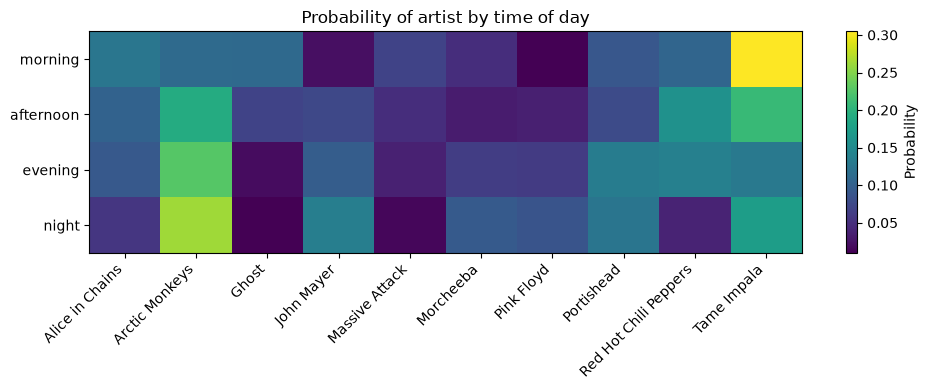

In [14]:
buckets = pd.DataFrame(np.eye(len(X.columns), dtype=int), columns=X.columns, index=X.columns)
probs = pd.DataFrame(clf.predict_proba(buckets), columns=clf.classes_, index=buckets.index)
probs = probs.reindex(['morning', 'afternoon', 'evening', 'night'])
print(probs.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(probs.values, aspect='auto')
ax.set_xticks(range(len(probs.columns)))
ax.set_xticklabels(probs.columns, rotation=45, ha='right')
ax.set_yticks(range(len(probs.index)))
ax.set_yticklabels(probs.index)
fig.colorbar(im, label='Probability')
ax.set_title('Probability of artist by time of day')
plt.tight_layout()
plt.show()

Aggregate the data into daily scrobbles

In [15]:
daily = scrobbles.groupby('date_only').size().reset_index(name='scrobble_count')
daily['date_only'] = pd.to_datetime(daily['date_only'])
daily.set_index('date_only', inplace=True)

In [16]:
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
for i in range(7):
    daily[days[i]] = (daily.index.dayofweek == i).astype(float)

In [17]:
monthly = scrobbles.groupby('month').size().reset_index(name='scrobble_count')
monthly

,month,scrobble_count
0,2025-11,1254
1,2025-12,1732
2,2026-01,1692
3,2026-02,1345
4,2026-03,1022
5,2026-04,522
6,2026-05,829
7,2026-06,1942
8,2026-07,2479
9,2026-08,2430


Output the data to csv's so that I don't have to request the data each time I run the program

In [18]:
scrobbles.to_csv('datasets/scrobbles.csv', index=False)

In [19]:
daily.to_csv('datasets/daily.csv', index=True)

Initial linear regression doesn't fit quite so well

C:\Users\markl\pipx\venvs\jupyterlab\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Text(0, 0.5, 'Scrobbles per Day')

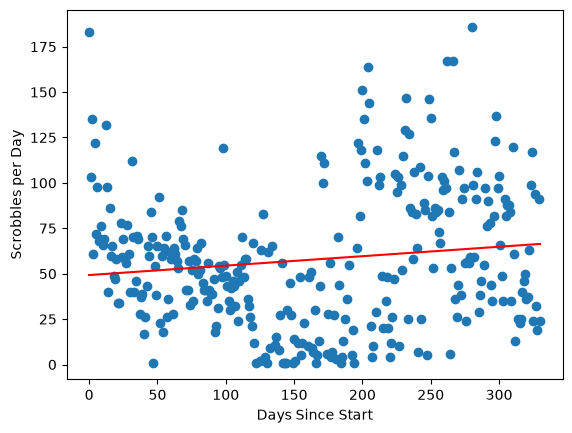

In [20]:
daily['days_since_start'] = (daily.index - daily.index[0]).days

X = daily[['days_since_start']]
y = daily['scrobble_count']

model = LinearRegression(fit_intercept=True)
model.fit(X, y)

xfit = np.linspace(X.min().iloc[0], X.max().iloc[0], 1000)
yfit = model.predict(xfit[:, np.newaxis])

plt.scatter(X, y)
plt.plot(xfit, yfit, color='red')
plt.xlabel('Days Since Start')
plt.ylabel('Scrobbles per Day')

Polynomial w/ a degree of 2 fits better

C:\Users\markl\pipx\venvs\jupyterlab\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


Text(0, 0.5, 'Scrobbles per Day')

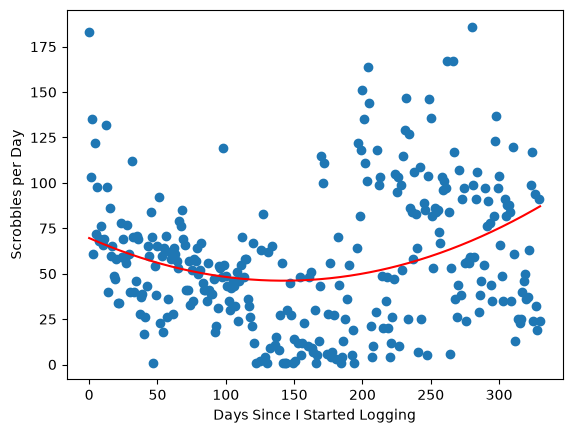

In [21]:
daily["days_since_start"] = (daily.index - daily.index[0]).days

X = daily[["days_since_start"]]
y = daily["scrobble_count"]

poly_model = make_pipeline(PolynomialFeatures(2), LinearRegression())

poly_model.fit(X, y)

xfit = np.linspace(X.min().iloc[0], X.max().iloc[0], 1000)
yfit = poly_model.predict(xfit[:, np.newaxis])

plt.scatter(X, y)  
plt.plot(xfit, yfit, color="red")
plt.xlabel("Days Since I Started Logging")
plt.ylabel("Scrobbles per Day")

Using the [unofficial docs](https://lastfm-docs.github.io/api-docs/user/getLovedTracks/#examples) once again, the data can be combined with the ```User.getLovedTracks``` endpoint. A new field called ```is_loved``` can be joined to the full scrobble dataset

In [22]:
all_loved_tracks = []
loved_page = 1
total_loved_pages = 1

while loved_page <= total_loved_pages:
    response = requests.get('http://ws.audioscrobbler.com/2.0/', params={
        'method': 'user.getlovedtracks',
        'user': USERNAME,
        'api_key': API_KEY,
        'format': 'json',
        'limit': 200,
        'page': loved_page
    })
    data = response.json()
    if loved_page == 1:
        total_loved_pages = int(data['lovedtracks']['@attr']['totalPages'])
    tracks = data['lovedtracks']['track']
    for track in tracks:
        all_loved_tracks.append({
            'artist': track['artist']['name'],
            'track': track['name'],
            'timestamp': int(track['date']['uts']) if 'date' in track else None
        })
    loved_page += 1

Merging the scrobbles and retrieved lovedScrobbles tracks on the columns ```artist``` and ```song``` against ```track``` and adding the new col ```is_loved``` 

In [23]:
lovedScrobbles = pd.DataFrame(all_loved_tracks)
lovedScrobbles['is_loved'] = 1
lovedScrobbles = lovedScrobbles.drop_duplicates(subset=['artist', 'track'])

lovedMerged = pd.merge(
    scrobbles,
    lovedScrobbles[['artist', 'track', 'is_loved']],
    left_on=['artist', 'song'],
    right_on=['artist', 'track'],
    how='left'
)

loved = lovedMerged.drop(columns=['track'])
loved['is_loved'] = loved['is_loved'].fillna(0).astype(int)
loved

,artist,album,song,url,date,timestamp,date_only,hour,tod,month,is_loved
0,Eagles,The Long Run (2013 Remaster),I Can't Tell You Why - 2013 Remaster,https://www.last.fm/music/Eagles/_/I+Can%27t+T...,2026-10-14 13:13:00,1791983602,2026-10-14,14,afternoon,2026-10,0
1,Ataxia,Automatic Writing,Another,https://www.last.fm/music/Ataxia/_/Another,2026-10-14 13:08:00,1791983297,2026-10-14,14,afternoon,2026-10,0
2,Jack White,Lazaretto,Would You Fight for My Love?,https://www.last.fm/music/Jack+White/_/Would+Y...,2026-10-14 12:59:00,1791982775,2026-10-14,13,afternoon,2026-10,1
3,Jack White,Frozen Charlotte,Neighbors Blues,https://www.last.fm/music/Jack+White/_/Neighbo...,2026-10-14 12:55:00,1791982528,2026-10-14,13,afternoon,2026-10,1
4,Jack White,no name,What's The Rumpus?,https://www.last.fm/music/Jack+White/_/What%27...,2026-10-14 12:50:00,1791982224,2026-10-14,13,afternoon,2026-10,0
...,...,...,...,...,...,...,...,...,...,...,...
17963,Tame Impala,Lonerism,Why Won't They Talk to Me?,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,2025-11-18 11:00:00,1763463648,2025-11-18,11,morning,2025-11,1
17964,Portishead,Portishead,Over,https://www.last.fm/music/Portishead/_/Over,2025-11-18 10:56:00,1763463370,2025-11-18,10,morning,2025-11,1
17965,Tame Impala,Deadbeat,Obsolete,https://www.last.fm/music/Tame+Impala/_/Obsolete,2025-11-18 10:47:00,1763462844,2025-11-18,10,morning,2025-11,1
17966,Tame Impala,Deadbeat,Piece Of Heaven,https://www.last.fm/music/Tame+Impala/_/Piece+...,2025-11-18 10:42:00,1763462559,2025-11-18,10,morning,2025-11,0


In [24]:
loved.to_csv('datasets/loved.csv', index=False)

In [25]:
spotify = pd.read_csv('datasets/spotify.csv')

Using a Spotify track dataset from [Kaggle](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset) which contains additional features such as ```danceability```, ```energy``` and ```tempo```

In order to get a higher match rate, the artist and track features are stripped and lowercase 

In [26]:
spotify['clean_artist'] = spotify['artists'].str.lower().str.strip()
spotify['clean_track'] = spotify['track_name'].str.lower().str.strip()

loved['clean_artist'] = loved['artist'].str.lower().str.strip()
loved['clean_track'] = loved['song'].str.lower().str.strip()

spotify_unique = spotify.drop_duplicates(subset=['clean_artist', 'clean_track'])

spotifyMerged = pd.merge(
    loved,
    spotify_unique,
    on=['clean_artist', 'clean_track'],
    how='left',
    indicator=True
)

matched_count = (spotifyMerged['_merge'] == 'both').sum()
total_count = len(loved)
match_rate = (matched_count / total_count) * 100

print(f"{matched_count} of {total_count} tracks match ({match_rate:.2f}%)")

6297 of 17968 tracks match (35.05%)


We make a new dataset called ```aggregated```

First we take one row per unique track w/ the spotify features selected in ```audio_cols```. 
Then we add the ```play_count``` for each track and remove any tracks that didn't match between the two datasets

The result is one row per matched track with the audio features and play count for each track. 

In [27]:
audio_cols = ['danceability', 'energy', 'valence', 'acousticness', 'instrumentalness', 'tempo', 'speechiness']

aggregated = spotifyMerged.groupby(['clean_artist', 'clean_track'])[audio_cols].first().reset_index()
aggregated['play_count'] = spotifyMerged.groupby(['clean_artist', 'clean_track'])['is_loved'].size().values
aggregated = aggregated.dropna(subset=['danceability', 'energy', 'valence'])
aggregated.to_csv('datasets/aggregatedData.csv', index=False)
aggregated

,clean_artist,clean_track,danceability,energy,valence,acousticness,instrumentalness,tempo,speechiness,play_count
4,a família,brinquedo assassino,0.771,0.746,0.502,0.090200,0.000000,148.054,0.2620,2
13,abba,super trouper,0.724,0.724,0.927,0.294000,0.000000,117.986,0.0304,1
14,adnan sami,tera chehra,0.646,0.562,0.488,0.523000,0.002100,100.000,0.0331,1
20,air,kelly watch the stars,0.516,0.743,0.226,0.282000,0.637000,109.837,0.0292,17
21,air,la femme d'argent,0.517,0.737,0.558,0.434000,0.684000,79.820,0.0352,20
...,...,...,...,...,...,...,...,...,...,...
2870,weezer,pork and beans,0.599,0.626,0.708,0.010800,0.000009,119.837,0.0339,1
2871,weezer,say it ain't so,0.635,0.551,0.451,0.007430,0.000018,151.779,0.0354,2
2873,weezer,the world has turned and left me here,0.455,0.918,0.560,0.000399,0.013400,99.078,0.0352,1
2874,weezer,undone - the sweater song,0.457,0.618,0.579,0.001140,0.002570,80.184,0.0296,1
